# 05. Empirical CDF closure and direct floor controls

Keep the **exact weighted empirical CDF in $u$** as the sole interpolation
method. First refine it using both template and likelihood accuracy, then
validate at reserved points. Next compare **direct fills** with and without the
observable floor, at standard and finer binning, and with nuisance interpolation of the MC bin yields. These are separate tests of interpolation and compression.

The baseline uses **no floor**, with the same filtered Unity evaluation, power
and bin count as the rerun notebook 04. No new samples or network training are needed. Numerical limits,
invalid fits and failed closure checks stay visible; a method is not accepted
merely because it reproduces its anchors.

### Parallel signal-reference study

This notebook parallels **09**. It uses $p(x;\eta)/p_S(x)$ with **$a=2$**
in place of $p(x;\eta)/p(x;1)$ with $a=100$. Both are normalized selected
shapes. The fixed process-ratio axes already use $p_S(x)$ and are unchanged.
The scalar observable remains frozen throughout each physical fit.

Keep the same run name, filtered ensembles, MC campaign, bin edges, physical
model, fit settings and study sequence. No additional reference events are
needed when the matching 10M cache exists. Notebook 04 fills new histograms
from those cached predictions and publishes `colab_04_baseline.json`;
05--07 require that completed manifest. Outputs and checkpoints are separate
from 08--11. Run **04, then 05, 06 and 07**; 07 uses direct templates and does
not require successful interpolation in 05.


Carry forward the accepted 04 baseline: **$a=2$, no floor, 36 moving bins**,
the same frozen filtered ratios, rates and normalizers, and at most **10M
selected events per source**. Keep bounded total-yield zeroing at 0.01 event
per bin and 0.05 events in total; larger negative means remain invalid.
The denser information plot in 04 did not change the baseline binning.

### Runtime and completed 04 baseline

Run all with the completed $a=2$, no-floor, 36-bin notebook **04** campaign.
Keep the same run name, filtered Unity ensemble and zeroing limits. Setup loads
a fresh pinned checkout; the next cell must report study version 5. There is
no need to rerun 04 if its final baseline-export cell completed successfully.

05 reuses the exact 04 bank and both saved unbinned benchmarks. Ratios are
verified and staged on Colab local disk once (about 1.4 GB for 10M events per
source). Anchor histograms are evaluated in chunks and cached as compact counts;
full coordinate sorting is unnecessary for this signal-reference map.
Interpolation refinement and fits still take CPU time. There is no generation,
NN evaluation or training, and no fallback to the old 250k integration bank.
The selected bank may not exceed 10M events per source.

In [1]:
import os
import sys
from pathlib import Path

RUN_NAME = "paper-distinct-s-v4"
MODE = os.environ.get("POODEMO_MODE", "production")  # production or smoke
CONFIG_OVERRIDES = {}  # e.g. {"quadrature_per_process": 500_000, "epochs": 150}
JAX_BACKEND = os.environ.get("POODEMO_JAX_BACKEND", "auto")  # auto, gpu, or cpu

SOURCE_COMMIT = "449be27b0b603c376fc94d00ff3738f65996e0e2"

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    import subprocess
    requested_backend = JAX_BACKEND.strip().lower()
    if requested_backend not in ("auto", "gpu", "cpu"):
        raise ValueError("JAX_BACKEND must be auto, gpu, or cpu")
    selected_backend = requested_backend
    if requested_backend == "auto":
        try:
            gpu_probe = subprocess.run(["nvidia-smi", "--query-gpu=name", "--format=csv,noheader"],
                                       capture_output=True, text=True, timeout=10)
            gpu_present = gpu_probe.returncode == 0 and bool(gpu_probe.stdout.strip())
        except (OSError, subprocess.TimeoutExpired):
            gpu_present = False
        selected_backend = "gpu" if gpu_present else "cpu"
    # CUDA-only selection fails visibly if initialization fails. Keep PyTorch's
    # CUDA visibility and avoid JAX reserving most GPU memory before training.
    jax_platform = "cuda" if selected_backend == "gpu" else "cpu"
    os.environ["JAX_PLATFORMS"] = jax_platform
    os.environ.setdefault("XLA_PYTHON_CLIENT_PREALLOCATE", "false")
    from google.colab import drive
    drive.mount("/content/drive", force_remount=False)
    ROOT = Path(os.environ.get("POODEMO_ROOT", f"/content/drive/MyDrive/poodemo/runs/{RUN_NAME}"))
    import tempfile
    # Download afresh even in a reused runtime; do not alter older checkouts.
    REPO_DIR = Path(tempfile.mkdtemp(prefix="poodemo-05-", dir="/content"))
    print(f"Notebook 05 source: {SOURCE_COMMIT} (fresh download)")
    if not (REPO_DIR / "pyproject.toml").exists():
        import getpass
        import io
        import shutil
        import tarfile
        import urllib.error
        import urllib.request

        archive_url = f"https://api.github.com/repos/rafaellopesdesa/poodemo/tarball/{SOURCE_COMMIT}"

        def fetch_source(token=None):
            headers = {"Accept": "application/vnd.github+json", "User-Agent": "poodemo-colab"}
            if token:
                headers["Authorization"] = "Bearer " + token
            request = urllib.request.Request(archive_url, headers=headers)
            with urllib.request.urlopen(request, timeout=180) as response:
                return response.read()

        try:
            archive_bytes = fetch_source()
        except urllib.error.HTTPError as error:
            if error.code not in (401, 403, 404):
                raise RuntimeError(f"Repository download failed (HTTP {error.code}).") from None
            token = None
            try:
                from google.colab import userdata
                token = userdata.get("GITHUB_TOKEN")
            except Exception:
                pass
            if not token:
                token = getpass.getpass("GitHub token with read access to poodemo: ").strip()
            if not token:
                raise RuntimeError("Provide a GitHub token with read access to download the pinned notebook 05 source.")
            try:
                archive_bytes = fetch_source(token)
            except urllib.error.HTTPError as auth_error:
                raise RuntimeError(f"Repository download failed (HTTP {auth_error.code}); check token access.") from None
            finally:
                token = None

        # Validate archive paths and reject links before extracting the source.
        with tempfile.TemporaryDirectory(prefix="poodemo-source-") as temp:
            staging = Path(temp).resolve()

            def safe_destination(name):
                destination = (staging / name).resolve()
                if not destination.is_relative_to(staging):
                    raise RuntimeError("Unsafe path in source archive.")
                return destination

            with tarfile.open(fileobj=io.BytesIO(archive_bytes), mode="r:gz") as archive:
                for entry in archive.getmembers():
                    safe_destination(entry.name)
                    if not (entry.isfile() or entry.isdir()):
                        raise RuntimeError("Links and special files are not supported in the source archive.")
                archive.extractall(staging)
            candidates = [p.parent for p in staging.rglob("pyproject.toml") if (p.parent / "poodemo").is_dir()]
            if len(candidates) != 1:
                raise RuntimeError("The downloaded archive must contain one poodemo repository checkout.")
            shutil.copytree(candidates[0], REPO_DIR, dirs_exist_ok=True)
        del archive_bytes

    if os.environ.get("POODEMO_SKIP_INSTALL") != "1":
        from importlib.metadata import version, PackageNotFoundError
        # JAX discovers every installed plugin, even when selecting CPU.
        # Retain already-matched CUDA 12 packages when rerunning GPU setup.
        remove_plugins = []
        for package in ("jax-cuda12-plugin", "jax-cuda12-pjrt", "jax-cuda13-plugin", "jax-cuda13-pjrt"):
            try:
                installed_version = version(package)
            except PackageNotFoundError:
                continue
            if not (selected_backend == "gpu" and package.startswith("jax-cuda12-") and installed_version == "0.5.3"):
                remove_plugins.append(package)
        if remove_plugins:
            subprocess.check_call([sys.executable, "-m", "pip", "uninstall", "-y", "-q", *remove_plugins])
        gpu_requirements = (["jax==0.5.3", "jaxlib==0.5.3",
                             "jax-cuda12-plugin[with-cuda]==0.5.3", "jax-cuda12-pjrt==0.5.3"]
                            if selected_backend == "gpu" else [])
        # Resolve with the base requirements so PyTorch's CUDA dependencies are
        # considered together with JAX's. Avoid blanket --upgrade changes.
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-r",
                               str(REPO_DIR / "requirements-colab.txt"), *gpu_requirements])
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-e", str(REPO_DIR)])

        # Check the live notebook kernel before any expensive network training.
        import jax
        import jaxlib
        import jax.numpy as jnp
        if jax.__version__ != "0.5.3" or jaxlib.__version__ != "0.5.3":
            raise RuntimeError("JAX packages are stale in this kernel. Restart the runtime and rerun setup.")
        if selected_backend == "gpu":
            for package in ("jax-cuda12-plugin", "jax-cuda12-pjrt"):
                if version(package) != "0.5.3":
                    raise RuntimeError(f"{package} must match JAX 0.5.3. Restart the runtime and rerun setup.")
        jax.config.update("jax_platforms", jax_platform)
        jax.config.update("jax_enable_x64", True)
        try:
            jax_devices = jax.devices()
            if not jax_devices or any(device.platform != selected_backend for device in jax_devices):
                raise RuntimeError(f"Expected {selected_backend} devices; found {jax_devices}")
            probe_value, probe_gradient = jax.jit(jax.value_and_grad(lambda x: jnp.sum(x*x)))(
                jnp.asarray([1., 2., 3.], dtype=jnp.float64))
            probe_gradient.block_until_ready()
            if (float(probe_value) != 14. or list(probe_gradient) != [2., 4., 6.]
                    or probe_gradient.dtype != jnp.float64
                    or any(device.platform != selected_backend for device in probe_gradient.devices())):
                raise RuntimeError("JAX double-precision value/gradient check failed")
        except Exception as error:
            raise RuntimeError(
                f"JAX {selected_backend} startup failed. Select a Colab GPU runtime if requesting GPU, "
                "then restart the runtime and rerun setup. Use JAX_BACKEND='cpu' only for an intentional CPU run."
            ) from error
        print(f"JAX {jax.__version__} / jaxlib {jaxlib.__version__}: backend={selected_backend}, {jax_devices}; float64 JIT/gradient OK")

    # A new editable install is not activated in an already-running kernel.
    # Expose the inner package directly, including after a failed import cached
    # the outer /content/poodemo checkout as a namespace package.
    import importlib
    source_root = str(REPO_DIR.resolve())
    if source_root in sys.path:
        sys.path.remove(source_root)
    sys.path.insert(0, source_root)
    importlib.invalidate_caches()
    # Run from the top: subsequent cells recreate objects from this checkout.
    # Clear all poodemo submodules, including old plotting and fit functions.
    for module_name in list(sys.modules):
        if module_name == "poodemo" or module_name.startswith("poodemo."):
            del sys.modules[module_name]

else:
    # Locally: pip install -r requirements-colab.txt && pip install -e .
    ROOT = Path(os.environ.get("POODEMO_ROOT", str(Path.home() / "poodemo-runs" / RUN_NAME)))
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "poodemo" / "pipeline.py").exists():
            sys.path.insert(0, str(candidate))
            break

ROOT.mkdir(parents=True, exist_ok=True)
print(f"Run directory: {ROOT}")
print(f"Mode: {MODE}")

Mounted at /content/drive
Notebook 05 source: 449be27b0b603c376fc94d00ff3738f65996e0e2 (fresh download)


/tmp/ipykernel_2006/149409317.py:99: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  archive.extractall(staging)


JAX 0.5.3 / jaxlib 0.5.3: backend=gpu, [CudaDevice(id=0)]; float64 JIT/gradient OK
Run directory: /content/drive/MyDrive/poodemo/runs/paper-distinct-s-v4
Mode: production


In [2]:
import poodemo.reference_splines as _reference_splines

_expected_methods = ("ecdf_u",)
_loaded_methods = tuple(getattr(_reference_splines, "METHODS", ()))
if _loaded_methods != _expected_methods or getattr(_reference_splines, "STUDY_VERSION", 0) != 5:
    raise RuntimeError(
        f"Old interpolation code is loaded: {_loaded_methods}. "
        "Run this notebook from the setup cell at the top before starting the study.")
if IN_COLAB:
    _expected_source = (REPO_DIR / "poodemo" / "reference_splines.py").resolve()
    if Path(_reference_splines.__file__).resolve() != _expected_source:
        raise RuntimeError("The interpolation module was not loaded from this run's fresh checkout.")
print("Verified notebook 05 study version:", _reference_splines.STUDY_VERSION)
print("Verified interpolation methods:", ", ".join(_loaded_methods))
print("Interpolation module:", _reference_splines.__file__)
from poodemo.signal_reference import signal_log_ratio
print("Signal-reference coordinate available:", signal_log_ratio.__module__)

Verified notebook 05 study version: 5
Verified interpolation methods: ecdf_u
Interpolation module: /content/poodemo-05-mzipzz0w/poodemo/reference_splines.py
Signal-reference coordinate available: poodemo.signal_reference


In [3]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from poodemo.pipeline import create_run

run = create_run(ROOT, mode=MODE, overrides=CONFIG_OVERRIDES)
# Observable-only settings: keep these identical in notebooks 04 and 05.
# The floor changes the observable, never the physical mu or its fit bounds.
N_BINS = 36
REFERENCE_RATIO_ETA_MIN = 0.0  # No floor.
REFERENCE_RATIO_A = 2.0
if not np.isfinite(REFERENCE_RATIO_A) or REFERENCE_RATIO_A <= 0:
    raise ValueError("REFERENCE_RATIO_A must be finite and positive")
if not np.isfinite(REFERENCE_RATIO_ETA_MIN) or not 0 <= REFERENCE_RATIO_ETA_MIN < 1:
    raise ValueError("REFERENCE_RATIO_ETA_MIN must lie in [0, 1)")
run = run.with_config(reference_ratio_denominator="S",
    reference_ratio_power=float(REFERENCE_RATIO_A),
    reference_ratio_eta_floor=float(REFERENCE_RATIO_ETA_MIN),
)
print(f"Reference ratio: {N_BINS} bins, eta floor={REFERENCE_RATIO_ETA_MIN:g}, "
      f"a={REFERENCE_RATIO_A:g}; 0.5 is inside a bin")
plt.rcParams.update({"figure.figsize": (7, 4.5), "axes.grid": True, "grid.alpha": 0.2})
display(pd.Series(run.config, name="configuration"))

# Bounded zeroing of TOTAL MC bin predictions, in expected event counts.
# Fixed before fitting; larger per-bin OR aggregate deficits remain invalid.
MC_ZERO_MAX_BIN = 0.01
MC_ZERO_MAX_TOTAL = 0.05
run = run.with_config(mc_zero_max_bin=MC_ZERO_MAX_BIN, mc_zero_max_total=MC_ZERO_MAX_TOTAL)
from poodemo.mc_yields import yield_policy
print("MC total-yield policy:", yield_policy(run.config).metadata())

Reference ratio: 36 bins, eta floor=0, a=2; 0.5 is inside a bin


,configuration
schema_version,7
mode,production
seed,20261006
physics_overrides,{}
toolkit_commit,fc09848fc6540fd32310faebbe9db6eea7ecd17b
n_per_sample,5000000
ni_sample_multiplier,10
generation_chunk,250000
preselection_train_cap,1000000
ratio_train_cap,2000000


MC total-yield policy: {'mc_yield_policy': 'bounded_zero_v1', 'mc_zero_max_bin': 0.01, 'mc_zero_max_total': 0.05}


### Tiny negative MC yields

After combining the signed components and applying the NI morph, replace a
negative **total bin mean** by zero only when every correction is at most
$0.01$ expected events and their sum at that parameter point is at most $0.05$.
Both limits are fixed before fitting and shared by 04 and 05. Larger deficits
remain invalid. Positive means, component templates and interference are unchanged;
the corrected total is used consistently in the Poisson rate and logarithm.

Save raw minima, affected bins and summed corrections. A zero prediction with a
positive observed count still has zero Poisson probability. Clipping creates
kinks: Fisher points with negative raw means or zero means with nonzero derivatives
remain invalid. This policy does not freeze $\eta$; the signal reference has no forced collapse at 1.

### Reuse notebook 03's filtered density ratios

Run notebook 03 with the transferred Unity models first. Keep the same
`RUN_NAME`, `MODE`, `CONFIG_OVERRIDES`, `UNITY_MODEL_DIR`, and
`ENSEMBLE_FILTER_POLICY` here. The default directory is
`My Drive/poodemo/unity_models/paper-distinct-s-v4-unity100/`; it contains
`bundle.json`, `campaign.json`, and `ratios/` directly inside it.

The next cell verifies the transferred bundle and reuses notebook 03's frozen
retained-member lists for all five ensembles, including the pointwise outlier
rules. It verifies input, policy and artifact hashes without re-screening or
evaluating analytical densities. Changed inputs require a completed matching
filter run in notebook 03 first; no networks are trained here. `RATIO_SOURCE = "drive"` explicitly
selects the original Drive models instead, with the same filtering rules.

The next cells verify the selected ensemble, then load the matching completed 04 bank.


In [4]:
import os
from pathlib import Path
from poodemo.data import save_json
from poodemo.ensemble_bundle import use_bundle, BundleEvaluationRun
from poodemo.member_filter import MemberFilterPolicy, unfiltered_run
from poodemo.practical import (PracticalRun, use_practical_run,
                               reuse_filtered_ensembles as filter_ratio_ensembles)

RATIO_SOURCE = "unity"  # "drive" explicitly selects the original saved models.
UNITY_MODEL_DIR = Path(os.environ.get(
    "POODEMO_UNITY_MODEL_DIR",
    "/content/drive/MyDrive/poodemo/unity_models/paper-distinct-s-v4-unity100",
))
ENSEMBLE_FILTER_POLICY = MemberFilterPolicy(
    catastrophic_peer_factor=100.0,
)  # Match notebook 03, including any custom policy settings.

# Unwrap a previous selection so rerunning this cell never nests evaluations.
source_run = run.base_run if isinstance(run, PracticalRun) else run
source_run = unfiltered_run(source_run)
source_run = source_run.base_run if isinstance(source_run, BundleEvaluationRun) else source_run
if RATIO_SOURCE == "unity":
    if not (UNITY_MODEL_DIR / "bundle.json").is_file():
        raise FileNotFoundError(
            f"Copy the complete Unity model bundle to {UNITY_MODEL_DIR}. "
            "Expected bundle.json, campaign.json and ratios/ directly inside it. "
            "Use the same directory as notebook 03; see unity/README.md.")
    ensemble_run = use_bundle(source_run, UNITY_MODEL_DIR)
elif RATIO_SOURCE == "drive":
    ensemble_run = source_run
else:
    raise ValueError("RATIO_SOURCE must be 'drive' or 'unity'")
run = filter_ratio_ensembles(ensemble_run, policy=ENSEMBLE_FILTER_POLICY)
filter_summary = pd.read_csv(run.path("results", "ensemble_filter", "summary.csv"))
display(filter_summary)
print("Ratio source:", RATIO_SOURCE)
print("Retained ratio models:", run.path("models", "ratios"))
print("Evaluation outputs:", run.evaluation_root)
save_json(run.path("results", "reference_ratio_model_source.json"), {
    "ratio_source": RATIO_SOURCE,
    "bundle_directory": str(ensemble_run.bundle) if RATIO_SOURCE == "unity" else None,
    "campaign_id": ensemble_run.bundle_manifest["campaign_id"] if RATIO_SOURCE == "unity" else None,
    "filter_identity": run.filter_manifest["identity"],
    "filter_policy": run.filter_manifest["inputs"]["policy"],
    "evaluation_root": str(run.evaluation_root),
})
_filtered_run = run
run = use_practical_run(run)
print("Practical evaluation:",run.evaluation_root)
# Preserve selected model provenance in the practical evaluation.
save_json(run.path("results","reference_ratio_model_source.json"),
          __import__("json").loads(_filtered_run.path("results","reference_ratio_model_source.json").read_text()))

Reusing frozen notebook-03 member selection: /content/drive/MyDrive/poodemo/runs/paper-distinct-s-v4/evaluations/paper-distinct-s-v4-unity100/1311f17de040bc40/filtered/a4a9405505b80e39


,task,original_members,retained_members,rejected_members,status,log_integral,max_point_mass,effective_fraction,log_normalization
0,SBI_over_S,100,100,0,passed,-0.000666,0.000005,0.989804,0.001621
1,B_over_S,100,100,0,passed,-0.000690,0.000005,0.987958,0.001652
2,NI_over_S,100,100,0,passed,-0.005577,0.000014,0.374248,0.007946
3,NI_up_over_NI,100,96,4,passed,0.000110,0.000012,0.412796,0.000183
4,NI_down_over_NI,100,96,4,passed,-0.000133,0.000015,0.340834,-0.000030


Ratio source: unity
Retained ratio models: /content/drive/MyDrive/poodemo/runs/paper-distinct-s-v4/evaluations/paper-distinct-s-v4-unity100/1311f17de040bc40/filtered/a4a9405505b80e39/models/ratios
Evaluation outputs: /content/drive/MyDrive/poodemo/runs/paper-distinct-s-v4/evaluations/paper-distinct-s-v4-unity100/1311f17de040bc40/filtered/a4a9405505b80e39
Practical evaluation: /content/drive/MyDrive/poodemo/runs/paper-distinct-s-v4/evaluations/paper-distinct-s-v4-unity100/1311f17de040bc40/filtered/a4a9405505b80e39/practical_v1


In [5]:
from poodemo.signal_reference import load_signal_baseline
from poodemo.colab_reference import ColabTemplateBank
_mc_base_run = run
run, samples_04 = load_signal_baseline(
    _mc_base_run, N_BINS, max_selected=10_000_000,
    local_cache=Path('/content/poodemo-05-ratios') if IN_COLAB else None,
)
print('Reusing completed notebook 04:',run.evaluation_root)
print('Selected events per source:',samples_04['target'])
print('No generation, neural evaluation or training is performed in 05.')
from poodemo.signal_benchmarks import load_signal_benchmarks, add_signal_benchmarks
reference_benchmarks, reference_provenance = load_signal_benchmarks(run)
print('References:', reference_benchmarks.model.unique().tolist())
print(reference_provenance['asimov_note'])


04 ratios verified/staged: S, 10,000,000 events
04 ratios verified/staged: SBI, 10,000,000 events
04 ratios verified/staged: B, 10,000,000 events
04 ratios verified/staged: NI, 10,000,000 events
04 ratios verified/staged: NI_up, 10,000,000 events
04 ratios verified/staged: NI_down, 10,000,000 events
Reusing completed notebook 04: /content/drive/MyDrive/poodemo/runs/paper-distinct-s-v4/evaluations/paper-distinct-s-v4-unity100/1311f17de040bc40/filtered/a4a9405505b80e39/practical_v1/results/colab_mc/8bfa628d6772d034e1c4/histograms/d9091abb61937f3f3881/inference_581b0fd4c797
Selected events per source: 10000000
No generation, neural evaluation or training is performed in 05.
References: ['analytic unbinned', 'learned unbinned (analytic Asimov)']
03 learned curve: physical Asimov; binned curves: same-template MC Asimov


### Shared 10M simulation baseline

The completed 04 manifest selects the same six labelled selected streams,
frozen rates, learned-map normalizers and filtered ensembles. Both direct fills
and exact empirical CDFs use these events. The analytical density is used only
for the saved unbinned benchmark. Asimov counts come from direct templates;
this is interpolation closure on a fixed MC bank, not independent MC closure.

### Ratio to the selected signal density

At nominal NI nuisance, define the learned, selected and normalized ratio
$$
R^S_\eta(x)=\frac{p(x;\eta_{\mathrm{eff}},0)}{p_S(x)},\qquad
\eta_{\mathrm{eff}}=\max(\eta,\eta_{\min}),\qquad
z^S_\eta(x)=\operatorname{sigmoid}\!\left(a\log R^S_\eta(x)\right).
$$
The baseline is **no floor**, **$a=2$**, and **36 bins**, so
$z^S_\eta=(R^S_\eta)^2/[1+(R^S_\eta)^2]$. The denominator is the selected pure-signal
shape, not the physical mixture at $\mu=1$. It stays fixed during every fit.

Use the same filtered learned component ratios $\hat r_j$, frozen normalizers
$Z_j=\langle\hat r_j\rangle_{S,\mathrm{MC}}$, and selected rates $\nu_j$:
$$
\hat f_\eta(x)=\sum_j c_j(\eta)\nu_j\hat r_j(x)/Z_j,\qquad
\nu_\eta=\sum_j c_j(\eta)\nu_j,\qquad
R^S_\eta=\frac{\hat f_\eta/\nu_\eta}{\hat f_S/\nu_S}.
$$
Here $\hat r_S=Z_S=1$, hence $\hat f_S/\nu_S=1$; the unknown common
$p_S(x)$ cancels. No analytical density is evaluated to define the observable.
Selected rates and normalizers never depend on data, toys or fitted parameters.
The extended Poisson term retains the event-rate information.

There is **no forced collapse at $\eta=1$**: the physical mixture generally
has a different shape from pure signal. Changing the reference can change
which information the scalar compression retains, but does not guarantee
sufficiency for a global fit over all physical $\mu$ or for NI profiling.
The sigmoid is invertible before binning; finite bins can lose information.

Retain the exact same half-step bin edges as 08--11, including 0.5 inside a
bin, for a controlled parallel. Physical coefficients, nuisance morphing,
fit bounds, MC prefixes and bounded total-yield zeroing are unchanged.
The explicit 0.2-floor control remains a separate study, not the baseline.

### Exact weighted empirical CDF in the signal log ratio

For the signal reference use the regular coordinate
$$
u^S_\eta(x)=\log R^S_\eta(x),\qquad
z^S_\eta=\operatorname{sigmoid}(a u^S_\eta),\qquad
u_b=\frac{\operatorname{logit}(z_b)}{a}.
$$
There is no division by $\eta-1$, score-limit substitution, reversal below 1,
or equality-collapse rule. Unlike notebook 09, the log ratio does not vanish
identically at 1. The original sigmoid edges map to fixed log-ratio boundaries.

At every anchor $\eta_k$, retain the exact weighted empirical CDF for each
component and NI variation:
$$
\widehat F_{j,k}(u)=\frac{\sum_i w_{ij}\mathbf{1}[u^S_{\eta_k}(x_i)\leq u]}
{\sum_i w_{ij}}.
$$
Use the same half-open bin convention as direct fills; endpoint bins include
the full support and ties stay together. Interpolate
convexly between neighboring $\eta$ anchors, preserving nonnegative component
bins and their totals. With fixed $u$ boundaries, this is also linear
interpolation of the anchor bin yields. It is exact at anchors on this finite
bank, while off-anchor accuracy still needs validation.

Because these boundaries are fixed, evaluate the CDF bin masses by streaming
direct anchor histograms and cache their compact counts. This gives exactly the
same empirical-CDF integrals without sorting or retaining full coordinate
arrays. No smooth density or additional events are introduced.

Keep the same refinement, held-out checks and nuisance treatments as 09.
The extra anchors near 1 are retained for the parallel
comparison, although there is no special contraction there in this family.

### Likelihood-sensitive refinement, followed by independent validation

Start with moderate anchors, focused around $\eta=1$. Each round checks template
midpoints using component errors scaled by $\sqrt{H+1}$ and Poisson deviances of
physical mixtures. The $+1$ is only a diagnostic scale, never a modified mean.
Signed physical coefficients and support mismatches are retained.

**New:** the displayed scan and additional predeclared quarter-interval points
also check $\Delta q$ against direct fits, with NI fixed and profiled. Failing
likelihood points request new neighboring anchors, without turning the checked
point itself into a knot. Direct reference fits are cached across rounds.
`max_anchors` and `max_rounds` bound the work; the history records template and
likelihood failures separately. The displayed scan now participates in refinement
and must not be described as independent validation.

After refinement stops, reserved irrational-fraction points in the final
intervals test templates; selected reserved points also test fits. These values
are never used to refine the grid. The summary reports `heldout_fit_checks` and
`heldout_q_failures` separately. Additional diagnostics retain sparse bins,
common-parameter objectives, full $(\mu,\alpha_{NI})$ surfaces and MLE shifts.
All fits use directly refilled Asimov counts and a fixed observable in numerator
and denominator. A numerical optimizer failure is accepted only if a feasible
candidate certifies the nonnegative NLL bound within $10^{-10}$; raw statuses
are saved. Other failures remain invalid.

The baseline has **no floor**. Adaptive anchors and reserved checks now cover
the region below $0.2$ as well; it is no longer an exact frozen plateau.
Power and binning remain fixed during this interpolation test.
Nuisance morphing is applied after bin integration, with the original Gaussian
constraint. No method is automatically promoted to downstream inference.

In [6]:
from poodemo.reference_splines import SplineStudySettings, run_reference_spline_comparison

SPLINE_BINS = N_BINS  # Must have been tested in the matching notebook 04 run.
SPLINE_SETTINGS = SplineStudySettings(
    initial_anchors=81,
    focus_anchors=81,
    focus_halfwidth=0.1,
    max_anchors=4801,
    max_rounds=12,
    max_bin_pull=0.05,
    max_deviance=0.005,
    q_tolerance=0.01,
    mle_tolerance=0.02,
    likelihood_refine_points=32,
    validation_intervals=96,
    validation_fit_points=8,
    surface_points=3,
    surface_mu_points=81,
    surface_alpha_points=41,
    cdf_cache_size=2,
)
print("CPU interpolation/fit study; no training. Full-event CDFs use bounded memory.")
print("Template and likelihood checks drive refinement; reaching a limit is a failed check.")

CPU interpolation/fit study; no training. Full-event CDFs use bounded memory.
Template and likelihood checks drive refinement; reaching a limit is a failed check.


In [7]:
cdf_bank = ColabTemplateBank(run, samples_04, SPLINE_BINS, SPLINE_SETTINGS.cdf_cache_size)
splines = run_reference_spline_comparison(run, n_bins=SPLINE_BINS, settings=SPLINE_SETTINGS, template_bank=cdf_bank)
splines = add_signal_benchmarks(splines, reference_benchmarks, reference_provenance)
display(splines["summary"])
print("Results:",splines["output"])

Exact weighted empirical CDF in u: round 0 (151 anchors)
  100 midpoint checks complete
  20/114 likelihood refinement points complete
  40/114 likelihood refinement points complete
  60/114 likelihood refinement points complete
  80/114 likelihood refinement points complete
  100/114 likelihood refinement points complete
  3 template and 22 likelihood checks failed
Exact weighted empirical CDF in u: round 1 (165 anchors)
  100 midpoint checks complete
  20/114 likelihood refinement points complete
  40/114 likelihood refinement points complete
  60/114 likelihood refinement points complete
  80/114 likelihood refinement points complete
  100/114 likelihood refinement points complete
  2 template and 13 likelihood checks failed
Exact weighted empirical CDF in u: round 2 (176 anchors)
  100 midpoint checks complete
  20/114 likelihood refinement points complete
  40/114 likelihood refinement points complete
  60/114 likelihood refinement points complete
  80/114 likelihood refinement po

,method,n_anchors,stop_reason,heldout_checks,heldout_failures,anchor_checks,anchor_failures,direct_physical_failures,fit_checks,off_anchor_fits,q_failures,heldout_fit_checks,heldout_q_failures,invalid_fits,max_abs_delta_q,mle_shift_flags,domain_mismatches,max_truth_nll,passed
0,ecdf_u,228,round_limit,134,1,228,0,0,184,178,7,18,3,4,0.059363,0,0,0.003722,False


Results: /content/drive/MyDrive/poodemo/runs/paper-distinct-s-v4/evaluations/paper-distinct-s-v4-unity100/1311f17de040bc40/filtered/a4a9405505b80e39/practical_v1/results/colab_mc/8bfa628d6772d034e1c4/histograms/d9091abb61937f3f3881/inference_581b0fd4c797/results/reference_ratio_interpolation


In [8]:
print("Refinement history (the displayed scan is part of refinement):")
display(splines["refinement"])
print("Reserved likelihood checks, never used for refinement:")
comparison = splines["comparison"]
reserved = comparison.loc[~comparison.used_for_refinement & ~comparison.on_scan & ~comparison.is_anchor]
display(reserved.assign(abs_delta_q=reserved.delta_q.abs()).nlargest(15, "abs_delta_q"))
print("Independent template checks with the largest physical-probe deviance:")
display(splines["validation"].query("role == 'heldout'").nlargest(15, "max_deviance"))
print("Coordinate checks at eta anchors, shown separately for each method:")
for method in splines["models"]:
    print(method)
    display(splines["validation"].query(
        "role == 'anchor_coordinate_check' and method == @method").nlargest(10, "max_deviance"))
print("Off-anchor fit discrepancies (invalid fits are listed separately):")
comparison = splines["comparison"]
off_anchor = comparison.loc[~comparison.is_anchor]
display(off_anchor.assign(abs_delta_q=off_anchor.delta_q.abs()).nlargest(15, "abs_delta_q"))
display(comparison.loc[~comparison.valid | ~comparison.valid_direct | comparison.mle_shift_flag])
print("Same-parameter objective errors, including nuisance excursions:")
fixed = splines["fixed_checks"]
display(fixed.assign(abs_delta_nll=fixed.delta_nll.abs()).nlargest(15, "abs_delta_nll"))
display(fixed.loc[fixed.finite_direct != fixed.finite_interpolated])
print("Zeroing at conditional and unrestricted fit points:")
display(splines["scans"].filter(regex="^(method|eta|systematics|valid|.*zeroed.*|.*raw_minimum.*|.*rejected_negative.*)$"))
print("Raw mixture errors are retained before zeroing:")
display(splines["validation"].nlargest(10,"raw_mixture_max_abs_error"))

Refinement history (the displayed scan is part of refinement):


,method,round,n_anchors,n_failed,q_checks,q_failed,worst_score,stop_reason
0,ecdf_u,0,151,3,228,22,inf,NaN
1,ecdf_u,1,165,2,228,13,inf,NaN
2,ecdf_u,2,176,2,228,8,inf,NaN
3,ecdf_u,3,183,1,228,6,inf,NaN
4,ecdf_u,4,189,1,228,5,inf,NaN
5,ecdf_u,5,195,1,228,4,inf,NaN
6,ecdf_u,6,200,1,228,4,inf,NaN
7,ecdf_u,7,205,1,228,4,inf,NaN
8,ecdf_u,8,210,1,228,4,inf,NaN
9,ecdf_u,9,215,1,228,4,inf,NaN


Reserved likelihood checks, never used for refinement:


,method,eta,mu,systematics,is_anchor,used_for_refinement,on_scan,q,valid,null_raw_minimum,...,mu_hat_direct,valid_direct,nll_best_direct,alpha_hat_direct,boundary_direct,delta_q,delta_mu_hat,q_passed,mle_shift_flag,abs_delta_q
0,ecdf_u,0.000006,0.000006,False,False,False,False,47.540290,True,0.0,...,1.0,True,3.411749e-29,0.000000e+00,False,0.059363,1.881698e-03,False,False,0.059363
2,ecdf_u,0.001300,0.001300,False,False,False,False,36.791065,True,0.0,...,1.0,True,3.004217e-29,0.000000e+00,False,0.038040,1.177759e-03,False,False,0.038040
3,ecdf_u,0.001300,0.001300,True,False,False,False,14.154536,True,0.0,...,1.0,True,6.199715e-14,-4.688032e-09,False,0.010748,1.555101e-03,False,False,0.010748
1,ecdf_u,0.000006,0.000006,True,False,False,False,19.774319,True,0.0,...,1.0,True,5.931780e-14,-4.583092e-09,False,0.005558,2.496445e-03,True,False,0.005558
181,ecdf_u,1.389184,1.389184,True,False,False,False,8.656646,True,0.0,...,1.0,True,3.045205e-15,7.158498e-10,False,0.002520,-7.032774e-05,True,False,0.002520
180,ecdf_u,1.389184,1.389184,False,False,False,False,10.279651,True,0.0,...,1.0,True,1.124760e-27,0.000000e+00,False,0.002449,-5.895105e-05,True,False,0.002449
35,ecdf_u,0.274592,0.274592,True,False,False,False,6.103693,True,0.0,...,1.0,True,1.757852e-14,-1.742141e-09,False,0.002252,5.188226e-05,True,False,0.002252
34,ecdf_u,0.274592,0.274592,False,False,False,False,6.115716,True,0.0,...,1.0,True,2.226039e-28,0.000000e+00,False,0.002233,4.046351e-05,True,False,0.002233
119,ecdf_u,0.953455,0.953455,True,False,False,False,0.094079,True,0.0,...,1.0,True,1.270486e-14,-1.278960e-09,False,-0.000130,-3.111207e-05,True,False,0.000130
118,ecdf_u,0.953455,0.953455,False,False,False,False,0.108266,True,0.0,...,1.0,True,3.397638e-28,0.000000e+00,False,-0.000119,-2.459591e-05,True,False,0.000119


Independent template checks with the largest physical-probe deviance:


,method,eta,role,max_bin_pull,max_deviance,support_mismatch,direct_invalid_bins,direct_zeroed_bins,interpolated_zeroed_bins,max_zeroed_total,raw_mixture_max_abs_error,passed
1,ecdf_u,0.000006,heldout,0.055843,0.004230,0,0,0,0,0.0,2.417186,False
13,ecdf_u,0.001300,heldout,0.036685,0.002817,0,0,0,0,0.0,1.937183,True
23,ecdf_u,0.014796,heldout,0.020447,0.001207,0,0,0,0,0.0,1.137106,True
43,ecdf_u,0.094184,heldout,0.017108,0.001090,0,0,0,0,0.0,0.901009,True
30,ecdf_u,0.036671,heldout,0.013092,0.001051,0,0,0,0,0.0,0.986546,True
33,ecdf_u,0.047092,heldout,0.016803,0.000983,0,0,0,0,0.0,0.992690,True
46,ecdf_u,0.129184,heldout,0.008785,0.000595,0,0,0,0,0.0,0.495046,True
19,ecdf_u,0.005486,heldout,0.009735,0.000481,0,0,0,0,0.0,0.669524,True
349,ecdf_u,1.284184,heldout,0.009629,0.000453,0,0,0,0,0.0,0.539841,True
40,ecdf_u,0.075668,heldout,0.010789,0.000413,0,0,0,0,0.0,0.741443,True


... (8 outputs left out)

Zeroing at conditional and unrestricted fit points:


,method,eta,systematics,valid,null_raw_minimum,null_zeroed_bins,null_zeroed_total,null_rejected_negative,best_raw_minimum,best_zeroed_bins,best_zeroed_total,best_rejected_negative
0,direct,0.000006,False,True,0.0,0,0.0,False,0.0,0,0.0,False
1,direct,0.000006,True,True,0.0,0,0.0,False,0.0,0,0.0,False
2,ecdf_u,0.000006,False,True,0.0,0,0.0,False,0.0,0,0.0,False
3,ecdf_u,0.000006,True,True,0.0,0,0.0,False,0.0,0,0.0,False
4,direct,0.001300,False,True,0.0,0,0.0,False,0.0,0,0.0,False
...,...,...,...,...,...,...,...,...,...,...,...,...
363,ecdf_u,1.389184,True,True,0.0,0,0.0,False,0.0,0,0.0,False
364,direct,1.400000,False,True,0.0,0,0.0,False,0.0,0,0.0,False
365,direct,1.400000,True,True,0.0,0,0.0,False,0.0,0,0.0,False
366,ecdf_u,1.400000,False,True,0.0,0,0.0,False,0.0,0,0.0,False


Raw mixture errors are retained before zeroing:


,method,eta,role,max_bin_pull,max_deviance,support_mismatch,direct_invalid_bins,direct_zeroed_bins,interpolated_zeroed_bins,max_zeroed_total,raw_mixture_max_abs_error,passed
1,ecdf_u,0.000006,heldout,0.055843,0.004230,0,0,0,0,0.0,2.417186,False
13,ecdf_u,0.001300,heldout,0.036685,0.002817,0,0,0,0,0.0,1.937183,True
23,ecdf_u,0.014796,heldout,0.020447,0.001207,0,0,0,0,0.0,1.137106,True
33,ecdf_u,0.047092,heldout,0.016803,0.000983,0,0,0,0,0.0,0.992690,True
30,ecdf_u,0.036671,heldout,0.013092,0.001051,0,0,0,0,0.0,0.986546,True
43,ecdf_u,0.094184,heldout,0.017108,0.001090,0,0,0,0,0.0,0.901009,True
40,ecdf_u,0.075668,heldout,0.010789,0.000413,0,0,0,0,0.0,0.741443,True
360,ecdf_u,1.389184,heldout,0.007465,0.000408,0,0,0,0,0.0,0.708858,True
19,ecdf_u,0.005486,heldout,0.009735,0.000481,0,0,0,0,0.0,0.669524,True
346,ecdf_u,1.249184,heldout,0.006965,0.000323,0,0,0,0,0.0,0.611796,True


In [9]:
# Verify anchor closure and component totals, including the regular eta=1 map.
for name, interpolator in splines["models"].items():
    for eta in (0., 1., float(interpolator.etas[-1])):
        direct = splines["bank"].exact(eta)
        np.testing.assert_allclose(interpolator(eta), direct, rtol=1e-12, atol=1e-10)
        np.testing.assert_allclose(direct.sum(axis=-1), splines["bank"].totals, rtol=1e-12)
    if REFERENCE_RATIO_ETA_MIN > 0:
        plateau = interpolator(np.array([0., REFERENCE_RATIO_ETA_MIN / 2, REFERENCE_RATIO_ETA_MIN]))
        np.testing.assert_allclose(plateau, np.broadcast_to(plateau[-1], plateau.shape), rtol=0., atol=1e-10)
print("Direct/ECDF anchors, component totals and any enabled floor plateau verified.")

Direct/ECDF anchors, component totals and any enabled floor plateau verified.


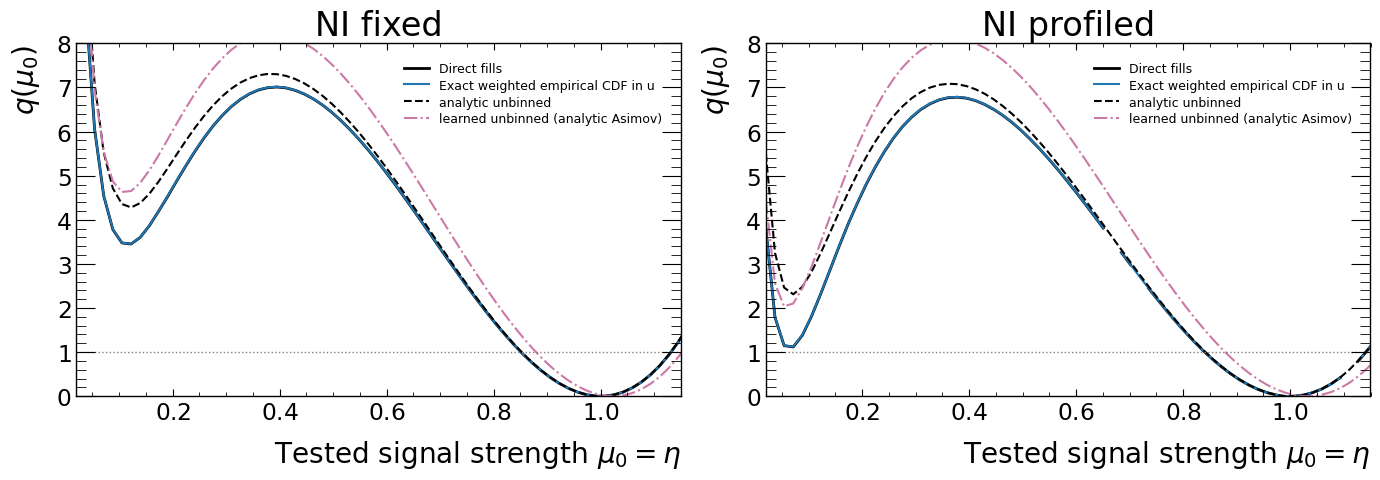

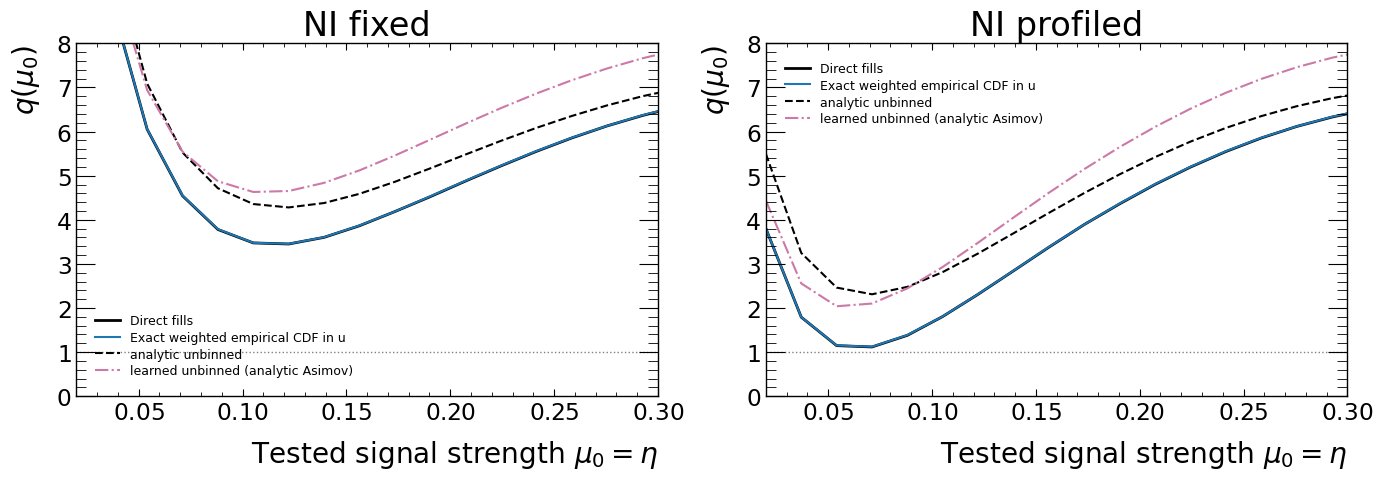

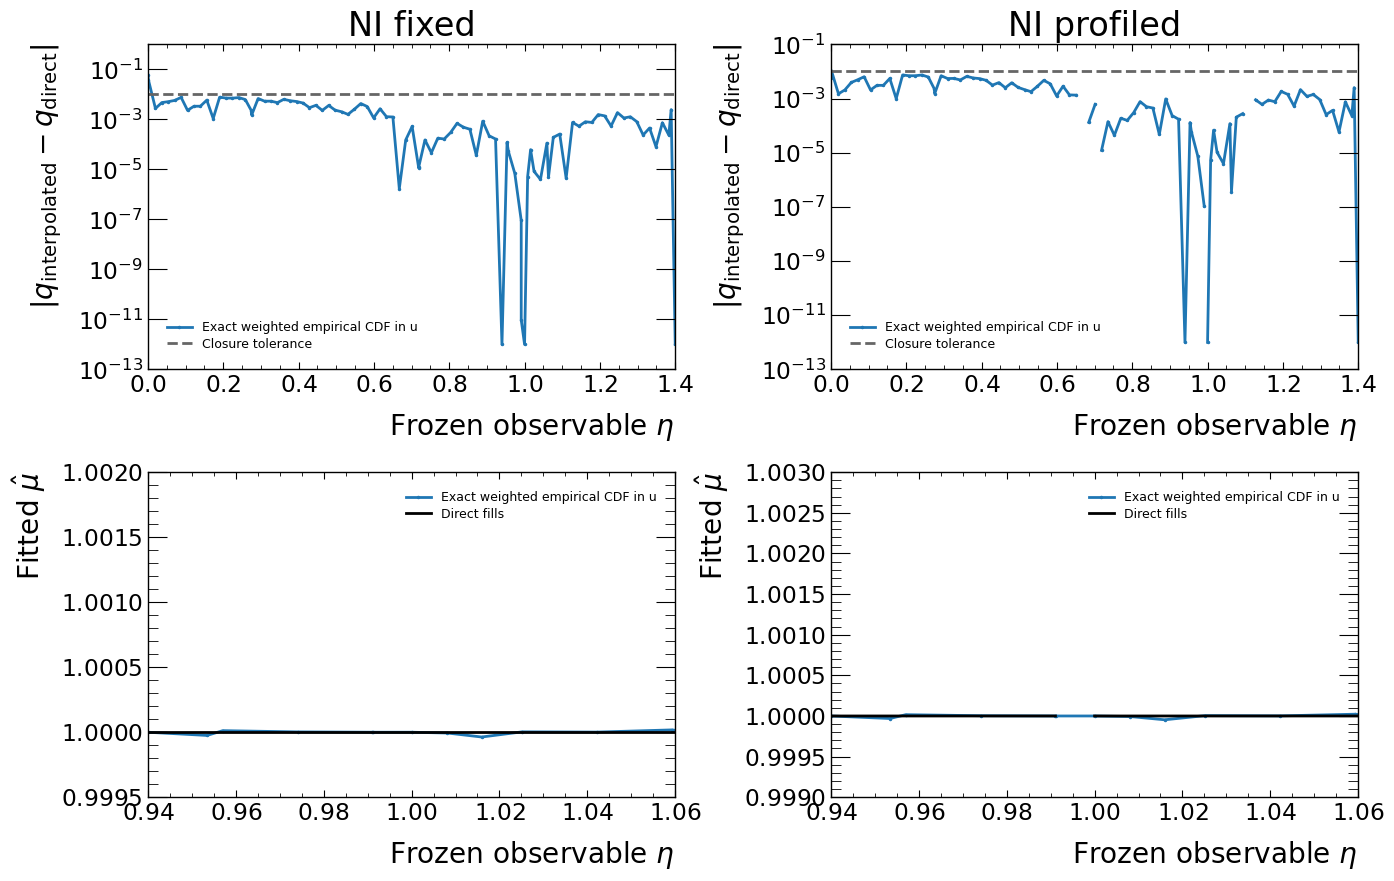

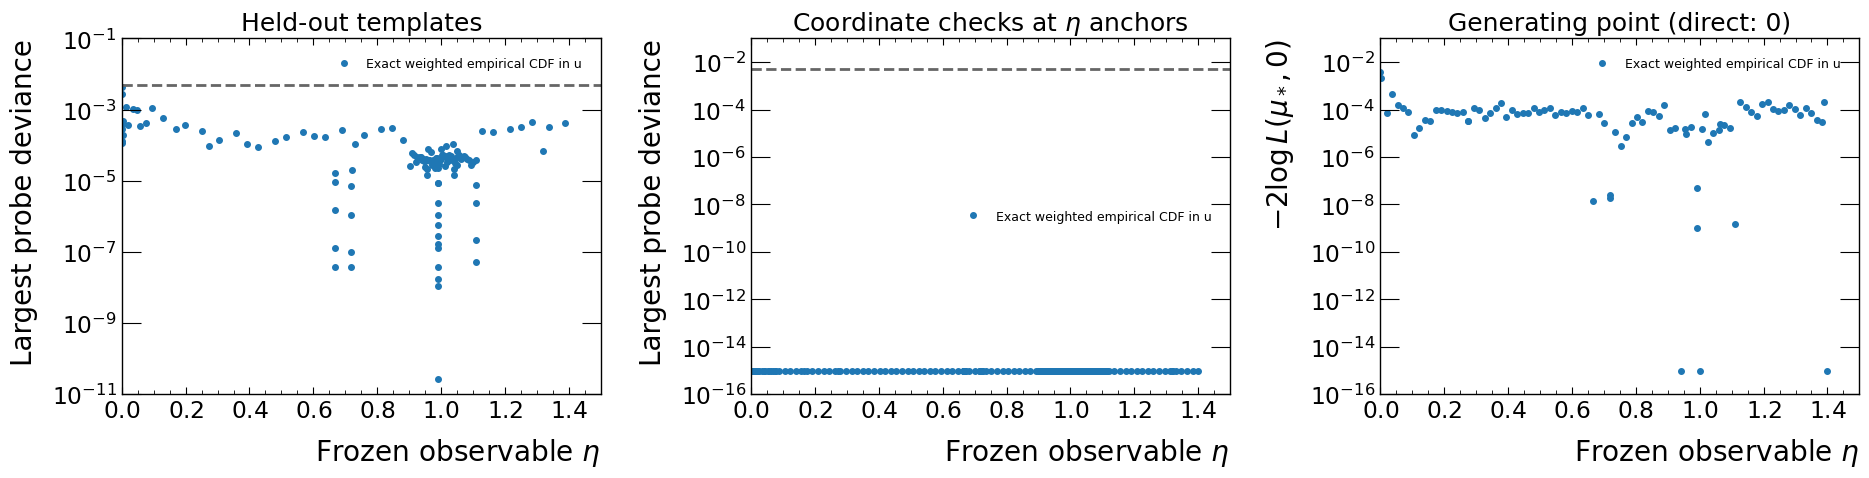

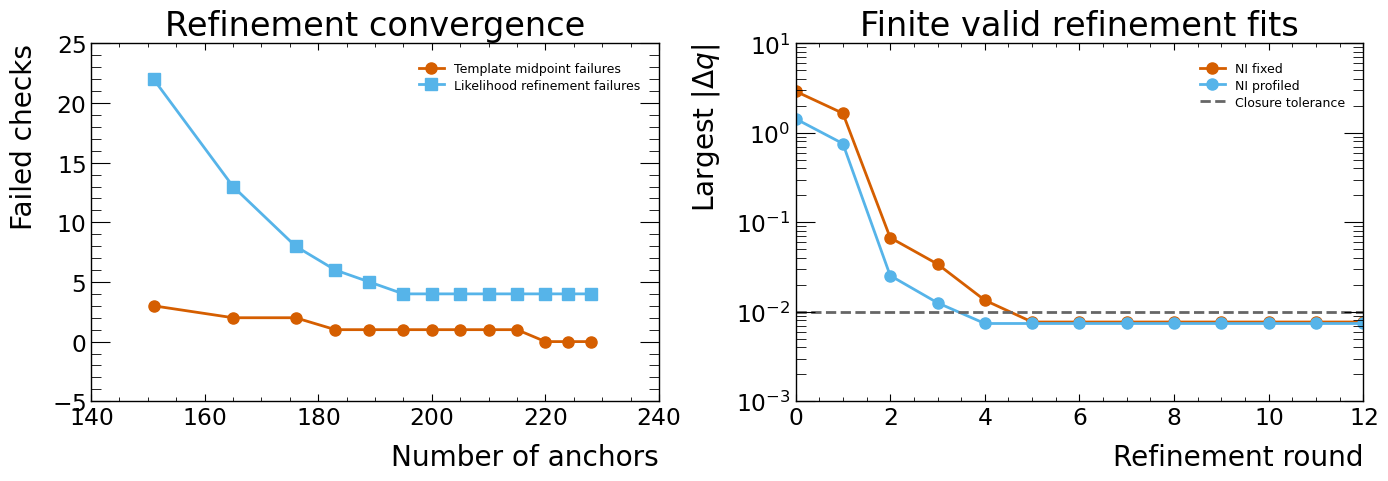

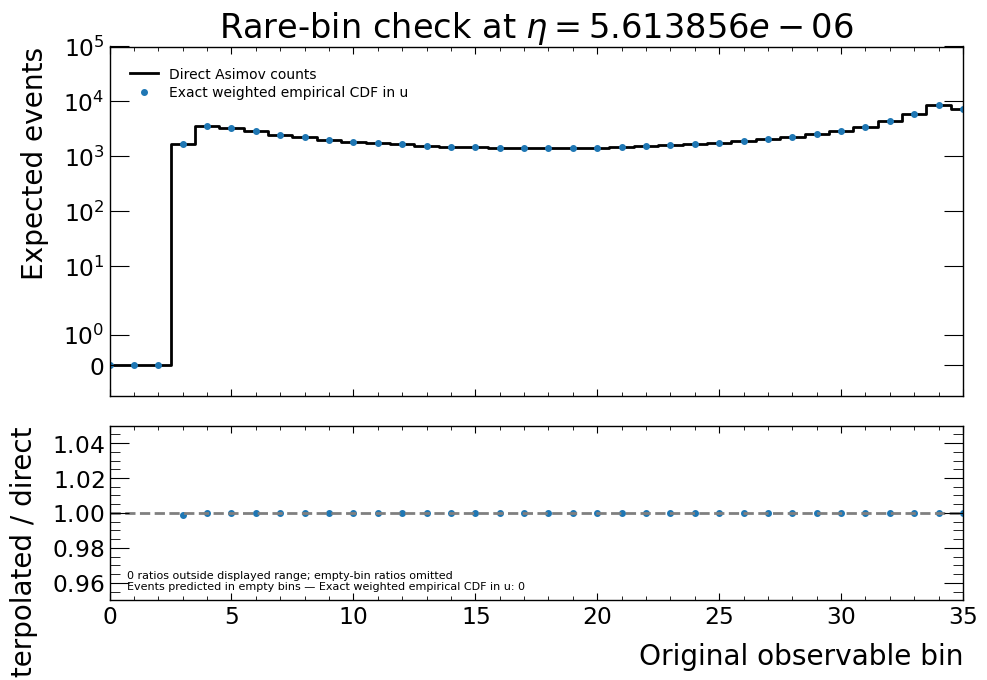

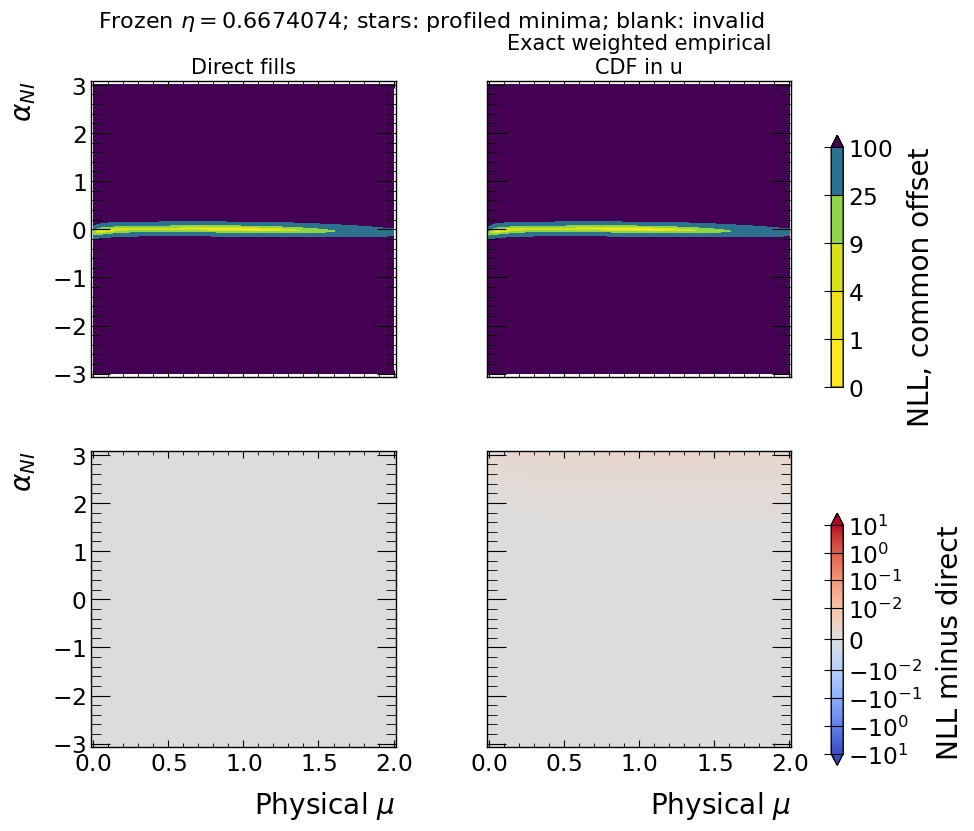

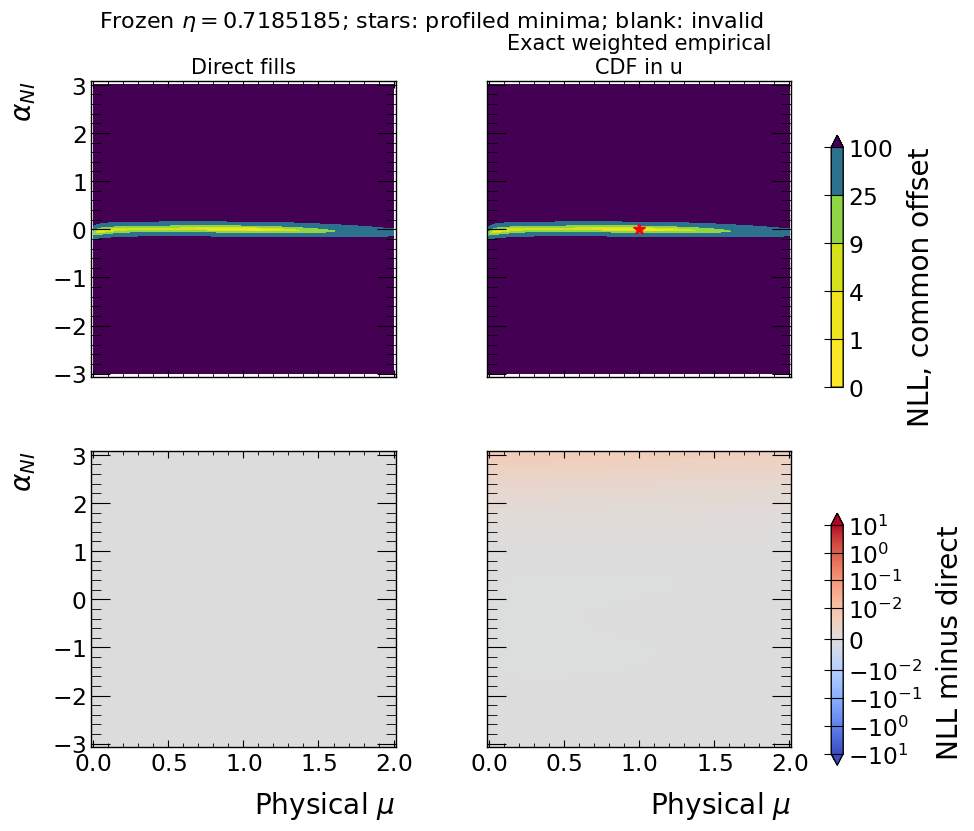

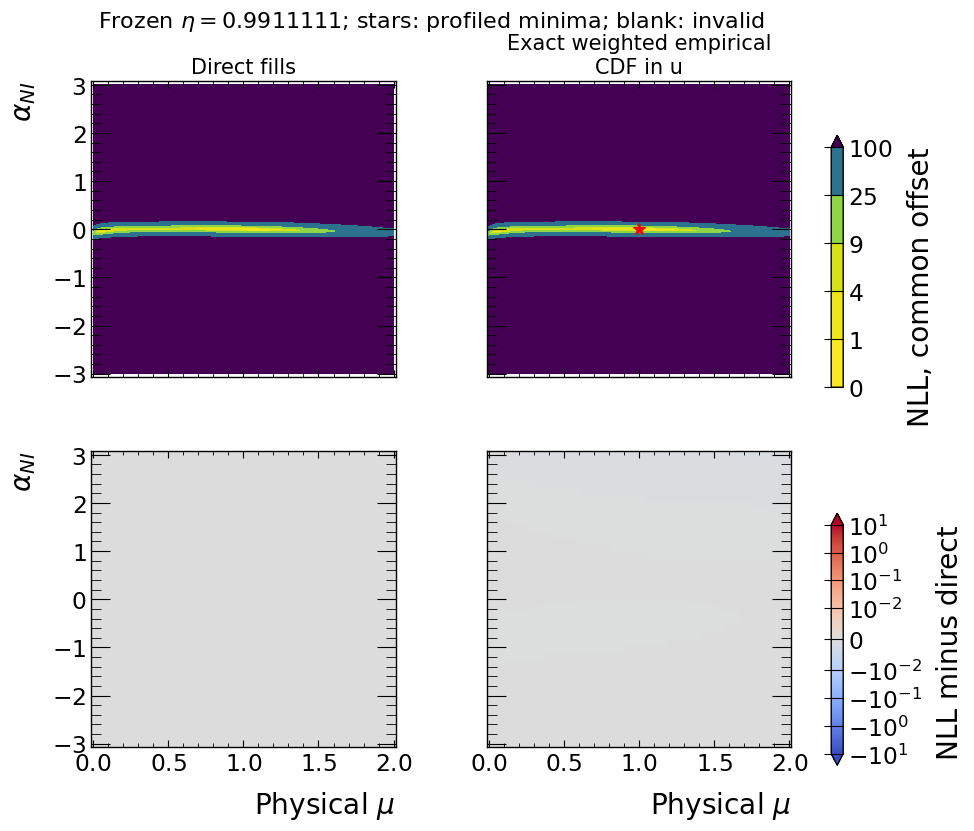

In [10]:
from poodemo.reference_spline_plots import plot_reference_spline_comparison

SCAN_XLIM = (0.02, 1.15)
SCAN_YLIM = (0, 8)
FOCUS_XLIM = (0.94, 1.06)
figures = plot_reference_spline_comparison(
    run, splines, scan_xlim=SCAN_XLIM, scan_ylim=SCAN_YLIM, focus_xlim=FOCUS_XLIM, secondary_xlim=(0.02, 0.30))
plt.show()

### Reading interpolation closure

Passing requires refinement convergence, reserved template and fit checks,
anchor closure, valid fits and matching physical domains. A finite validation
is not a coverage claim. Inspect invalid fits and MLE flags even if $q$ closes.
There is no forced collapse near $\eta=1$. Compression and finite MC can
still create competing minima; compare objectives before interpreting a
branch change as numerical failure.

Results and the empirical-CDF recipe are saved in
`results/reference_ratio_interpolation/`; figures are in `plots/05_interpolation/`.
The simulation bank and learned fields are fingerprinted and reused. Historical
spline products and notebook 04 results are not overwritten.

Direct-versus-interpolated fits test interpolation. The next study uses **only
direct fills**, so any remaining differences there cannot be blamed on CDF
interpolation. Notebook 03 retains its separate density-ratio learning checks.

The primary closure comparison is **interpolation versus direct fills on the
same 04 bank**, with 36 bins and $a=2$. Its numerical checks remain unchanged.
Analytical unbinned and learned unbinned curves are displayed separately,
including a zoom of the secondary minimum. Their gaps to the direct curve
already exist before interpolation and do not determine interpolation acceptance.
The learned reference is 03's physical-Asimov curve; the binned curves use
same-template MC Asimov counts. Their difference is therefore not a pure measure
of compression loss. Saved `benchmark_comparison.csv` tables label each reference.

The dense Fisher sweep in 04 was diagnostic only. Undefined Fisher points from
zero means with nonzero derivatives remain undefined; they do not select bins
or prevent this explicitly chosen 36-bin study. The 0.2-floor control remains
a diagnostic; no floor is restored to the baseline.


In [11]:
display(splines["morph_comparison"])
display(splines["summary"])
if not splines["summary"].passed.all():
    print("Some methods did not pass: inspect failures/limits before using their templates in inference.")
else:
    print("All methods passed the configured finite closure checks; inspect the MLE diagnostics as well.")
print("Saved tables:", splines["output"])
print("Saved figures:", run.path("plots", "05_interpolation"))

,eta,alpha_NI,l1_relative_difference,nll_difference


,method,n_anchors,stop_reason,heldout_checks,heldout_failures,anchor_checks,anchor_failures,direct_physical_failures,fit_checks,off_anchor_fits,q_failures,heldout_fit_checks,heldout_q_failures,invalid_fits,max_abs_delta_q,mle_shift_flags,domain_mismatches,max_truth_nll,passed
0,ecdf_u,228,round_limit,134,1,228,0,0,184,178,7,18,3,4,0.059363,0,0,0.003722,False


Some methods did not pass: inspect failures/limits before using their templates in inference.
Saved tables: /content/drive/MyDrive/poodemo/runs/paper-distinct-s-v4/evaluations/paper-distinct-s-v4-unity100/1311f17de040bc40/filtered/a4a9405505b80e39/practical_v1/results/colab_mc/8bfa628d6772d034e1c4/histograms/d9091abb61937f3f3881/inference_581b0fd4c797/results/reference_ratio_interpolation
Saved figures: /content/drive/MyDrive/poodemo/runs/paper-distinct-s-v4/evaluations/paper-distinct-s-v4-unity100/1311f17de040bc40/filtered/a4a9405505b80e39/practical_v1/results/colab_mc/8bfa628d6772d034e1c4/histograms/d9091abb61937f3f3881/inference_581b0fd4c797/plots/05_interpolation


### Direct controls: floor and bin resolution

Compare the no-floor baseline with floor $0.2$, using 36 and 144 bins.
Every curve uses the same learned map, direct simulation templates and NI morph
after histogramming. There is no analytical morph-before-bin comparison.
The feasible generating point certifies the direct Asimov denominator when
its NLL reaches zero. Conditional NI fits scan and refine resolved basins;
invalid fits and boundaries remain visible. This certificate does not apply
to imperfect interpolated templates.

In [12]:
from poodemo.reference_floor import FloorStudySettings, run_reference_floor_study, plot_reference_floor_study

FLOOR_SETTINGS = FloorStudySettings(
    comparison_floor=0.2,
    resolution_multiplier=4,  # 36 and 144 bins at the notebook default.
    alpha_grid_points=17,     # Refine each resolved conditional-NI basin.
    alpha_xtol=1e-7,
)
SECONDARY_XLIM = (0.02, 0.30)
print("Direct fills: floor 0 and the explicit comparison floor; standard/finer bins; morph MC templates after binning.")
print("This full-scan CPU control can take appreciable time, including the finer MC binning.")

Direct fills: floor 0 and the explicit comparison floor; standard/finer bins; morph MC templates after binning.
This full-scan CPU control can take appreciable time, including the finer MC binning.


In [13]:
floor_study = run_reference_floor_study(
    run, n_bins=SPLINE_BINS, template_bank=cdf_bank, settings=FLOOR_SETTINGS)
floor_study = add_signal_benchmarks(floor_study, reference_benchmarks, reference_provenance)
display(floor_study["summary"])
display(floor_study["scans"].loc[~floor_study["scans"].valid | floor_study["scans"].alpha_boundary])
print("Results:",floor_study["output"])

Direct floor/resolution/morph controls: 1/83, eta=0.02
Direct floor/resolution/morph controls: 2/83, eta=0.03703704
Direct floor/resolution/morph controls: 3/83, eta=0.05407407
Direct floor/resolution/morph controls: 4/83, eta=0.07111111
Direct floor/resolution/morph controls: 5/83, eta=0.08814815
Direct floor/resolution/morph controls: 6/83, eta=0.1051852
Direct floor/resolution/morph controls: 7/83, eta=0.1222222
Direct floor/resolution/morph controls: 8/83, eta=0.1392593
Direct floor/resolution/morph controls: 9/83, eta=0.1562963
Direct floor/resolution/morph controls: 10/83, eta=0.1733333
Direct floor/resolution/morph controls: 11/83, eta=0.1903704
Direct floor/resolution/morph controls: 12/83, eta=0.2074074
Direct floor/resolution/morph controls: 13/83, eta=0.2244444
Direct floor/resolution/morph controls: 14/83, eta=0.2414815
Direct floor/resolution/morph controls: 15/83, eta=0.2585185
Direct floor/resolution/morph controls: 16/83, eta=0.2755556
Direct floor/resolution/morph cont

,floor,n_bins,morph_order,systematics,fit_checks,valid_fits,truth_certificates,alpha_boundaries,invalid_fits
0,0.0,36,after,False,83,83,83,0,0
1,0.0,36,after,True,83,83,83,0,0
2,0.0,144,after,False,83,83,83,0,0
3,0.0,144,after,True,83,83,83,0,0
4,0.2,36,after,False,83,83,83,0,0
5,0.2,36,after,True,83,83,83,0,0
6,0.2,144,after,False,83,83,83,0,0
7,0.2,144,after,True,83,83,83,0,0


,eta,mu,eta_effective,floor,n_bins,morph_order,systematics,valid,raw_minimum,negative_bins,...,q,nll_null,nll_best,truth_certified,alpha_null,alpha_boundary,profile_basins,failed_searches,nfev,message


Results: /content/drive/MyDrive/poodemo/runs/paper-distinct-s-v4/evaluations/paper-distinct-s-v4-unity100/1311f17de040bc40/filtered/a4a9405505b80e39/practical_v1/results/colab_mc/8bfa628d6772d034e1c4/histograms/d9091abb61937f3f3881/inference_581b0fd4c797/results/reference_ratio_floor_study


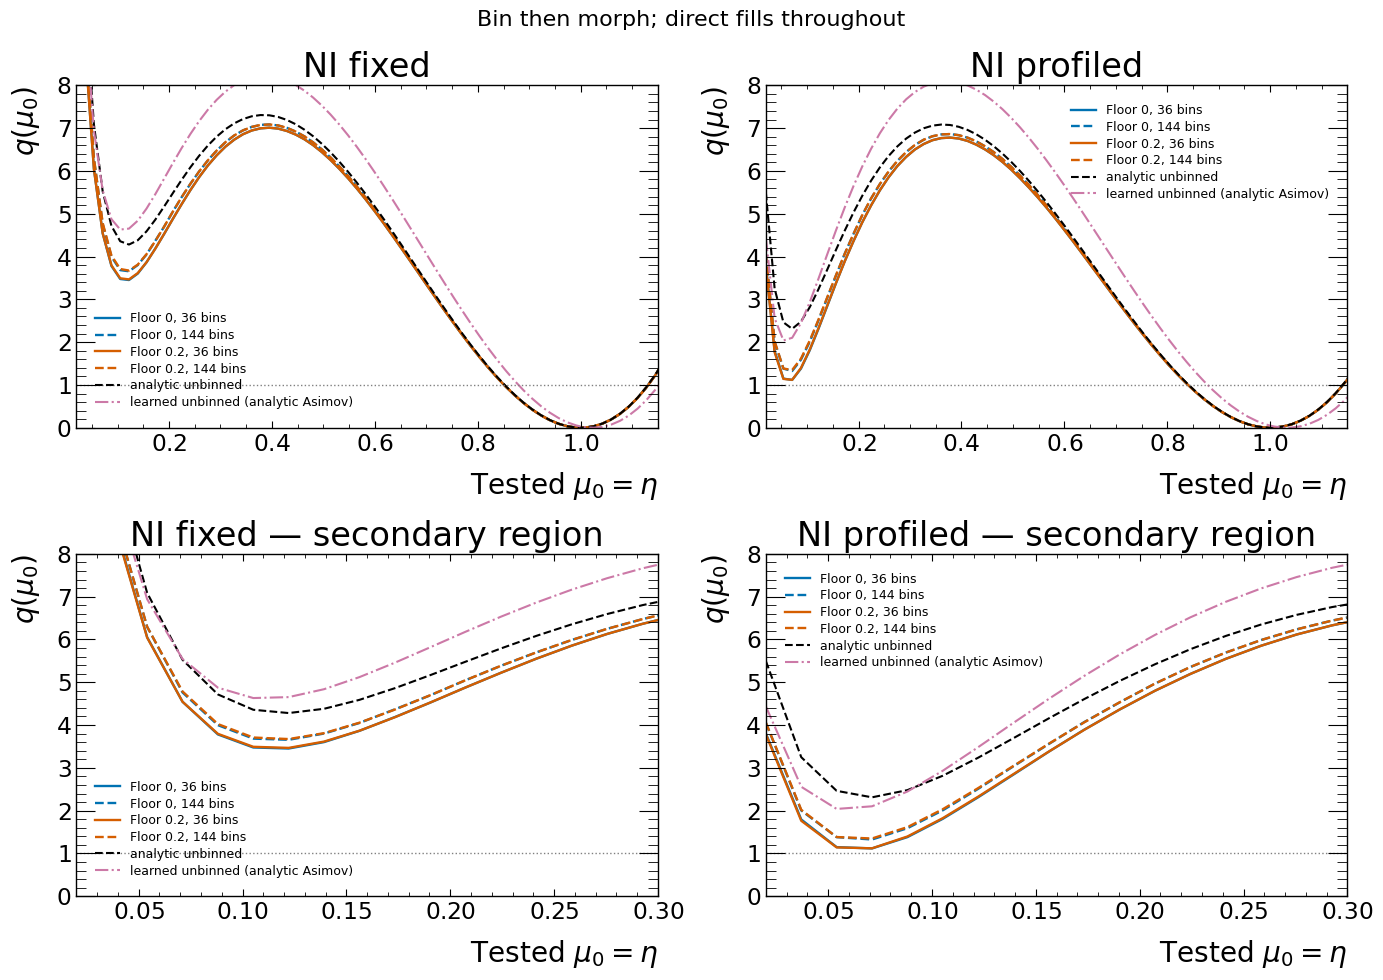

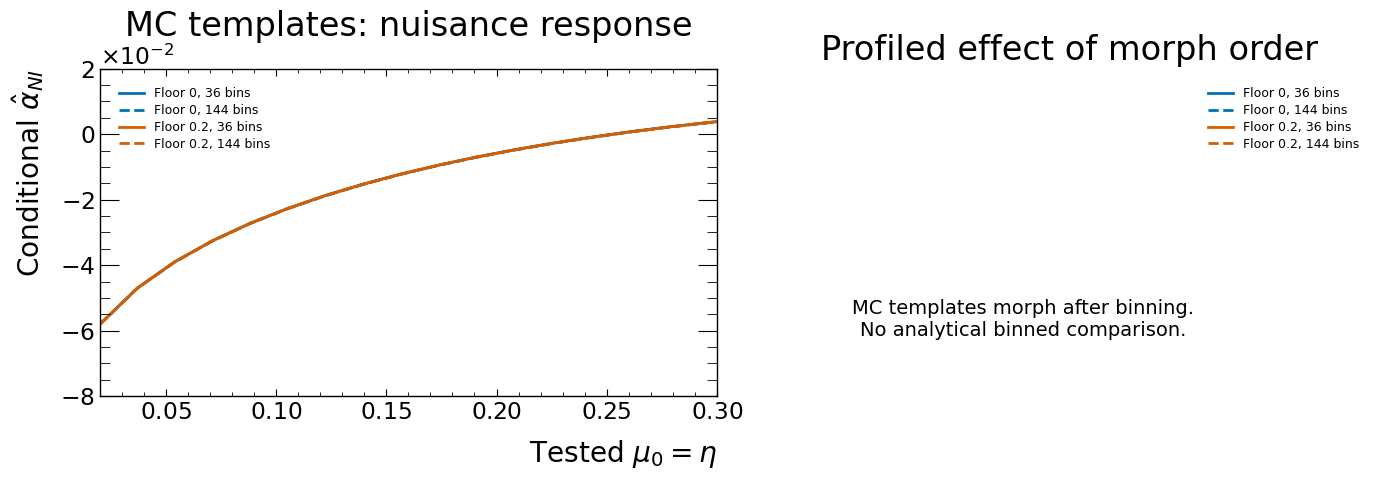

Largest profiled effects of removing the floor:


,eta,mu,eta_effective_no_floor,floor_no_floor,n_bins,morph_order,systematics,valid_no_floor,raw_minimum_no_floor,negative_bins_no_floor,...,nll_best_floor,truth_certified_floor,alpha_null_floor,alpha_boundary_floor,profile_basins_floor,failed_searches_floor,nfev_floor,message_floor,delta_q_no_floor_minus_floor,abs_delta_q
5,0.037037,0.037037,0.037037,0.0,36,after,True,True,0.0,0,...,1.330144e-27,True,-0.046982,False,1,0,27,Resolved basins and endpoints searched,0.029946,0.029946
23,0.105185,0.105185,0.105185,0.0,144,after,True,True,0.0,0,...,1.223268e-27,True,-0.022736,False,1,0,27,Resolved basins and endpoints searched,-0.026095,0.026095
19,0.088148,0.088148,0.088148,0.0,144,after,True,True,0.0,0,...,1.223268e-27,True,-0.027268,False,1,0,27,Resolved basins and endpoints searched,-0.025477,0.025477
15,0.071111,0.071111,0.071111,0.0,144,after,True,True,0.0,0,...,1.223268e-27,True,-0.032580,False,1,0,27,Resolved basins and endpoints searched,-0.023691,0.023691
1,0.020000,0.020000,0.020000,0.0,36,after,True,True,0.0,0,...,1.330144e-27,True,-0.058049,False,1,0,27,Resolved basins and endpoints searched,0.020095,0.020095
27,0.122222,0.122222,0.122222,0.0,144,after,True,True,0.0,0,...,1.223268e-27,True,-0.018802,False,1,0,27,Resolved basins and endpoints searched,-0.017476,0.017476
21,0.105185,0.105185,0.105185,0.0,36,after,True,True,0.0,0,...,1.330144e-27,True,-0.022688,False,1,0,27,Resolved basins and endpoints searched,-0.016047,0.016047
7,0.037037,0.037037,0.037037,0.0,144,after,True,True,0.0,0,...,1.223268e-27,True,-0.047017,False,1,0,27,Resolved basins and endpoints searched,-0.015554,0.015554
17,0.088148,0.088148,0.088148,0.0,36,after,True,True,0.0,0,...,1.330144e-27,True,-0.027222,False,1,0,27,Resolved basins and endpoints searched,-0.014608,0.014608
25,0.122222,0.122222,0.122222,0.0,36,after,True,True,0.0,0,...,1.330144e-27,True,-0.018753,False,1,0,27,Resolved basins and endpoints searched,-0.014270,0.014270


Direct controls all valid: True
MC nuisance templates are morphed after binning; no analytical binned control is used.


In [14]:
# This cell can reload the completed direct study without repeating any fits.
import json
import pandas as pd
from poodemo.reference_floor import plot_reference_floor_study

if "floor_study" not in globals():
    _floor_output = run.path("results", "reference_ratio_floor_study")
    floor_study = {name: pd.read_csv(_floor_output / f"{name}.csv", float_precision="round_trip")
                   for name in ("scans", "summary", "morph_comparison", "floor_comparison",
                                "reference_comparison", "unbinned")}
    floor_study["metadata"] = json.loads((_floor_output / "metadata.json").read_text())
    if floor_study["metadata"].get("status") != "complete":
        raise RuntimeError("The saved direct study is incomplete; run its fit cell first.")
    from poodemo.pipeline import observable_configuration
    if floor_study["metadata"].get("observable") != observable_configuration(run, "reference_ratio"):
        raise RuntimeError("Saved direct-study settings differ from the current baseline; rerun the direct study.")
    floor_study["output"] = _floor_output
    print("Reloaded completed direct study:", _floor_output)

floor_study = add_signal_benchmarks(floor_study, reference_benchmarks, reference_provenance)

# Also supports an already-running runtime that imported the older plot function.
with pd.option_context("compute.use_numexpr", False):
    floor_figures = plot_reference_floor_study(
        run, floor_study, scan_xlim=SCAN_XLIM, scan_ylim=SCAN_YLIM, secondary_xlim=SECONDARY_XLIM)
plt.show()
print("Largest profiled effects of removing the floor:")
floor_effect = floor_study["floor_comparison"].query("systematics")
display(floor_effect.assign(abs_delta_q=floor_effect.delta_q_no_floor_minus_floor.abs()).nlargest(15, "abs_delta_q"))
print("Direct controls all valid:", floor_study["metadata"]["all_fits_valid"])
print("MC nuisance templates are morphed after binning; no analytical binned control is used.")

### What these comparisons establish

Reserved direct-versus-ECDF comparisons isolate interpolation errors for the
same learned map and MC bank. Direct floor and resolution comparisons test
compression choices. Remaining gaps to analytical unbinned may include learned
ordering errors, finite MC, nuisance modeling and information lost in binning.
The MC Asimov closure alone is not independent-sample validation; use the paired
simulator toys and vary the MC cap to investigate these effects.